In [1]:
# Célula 1: Carregamento e Pré-processamento
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Carregar os dados novamente
df = pd.read_csv('../data/raw/day.csv')

# --- PRÉ-PROCESSAMENTO ---

# 2. Remover colunas problemáticas (Feature Selection)
# 'instant': é apenas um índice, não serve para prever.
# 'dteday': data em texto (já temos ano, mês e dia da semana numéricos).
# 'casual' e 'registered': VAZAMENTO DE DADOS (são partes da resposta).
# 'atemp': Redundante com 'temp' (correlação 0.99).
cols_to_drop = ['instant', 'dteday', 'casual', 'registered', 'atemp']
df_clean = df.drop(columns=cols_to_drop)

# 3. Codificação de Variáveis Categóricas (One-Hot Encoding)
# Variáveis como 'season' (1,2,3,4) e 'weathersit' (1,2,3) são categorias, não números progressivos.
# Vamos transformá-las em colunas binárias (0 ou 1).
categorical_cols = ['season', 'weathersit', 'mnth', 'weekday']
df_clean = pd.get_dummies(df_clean, columns=categorical_cols, drop_first=True)

# 4. Separar Features (X) e Alvo (y)
X = df_clean.drop('cnt', axis=1)  # Tudo menos o total de aluguéis
y = df_clean['cnt']               # Apenas o total de aluguéis

# --- DIVISÃO TREINO E TESTE ---

# 5. Dividir 70% Treino e 30% Teste (conforme o enunciado)
# random_state=42 garante que a divisão seja sempre a mesma (reprodutibilidade)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42)

# --- NORMALIZAÇÃO ---

# 6. Normalizar as variáveis numéricas
# Modelos lineares funcionam melhor quando todas as variáveis estão na mesma escala.
scaler = StandardScaler()

# Ajustamos o scaler APENAS nos dados de treino para evitar vazamento de informação do teste
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Mostrando o resultado final das dimensões
print(f"Tamanho do Treino: {X_train.shape[0]} linhas")
print(f"Tamanho do Teste: {X_test.shape[0]} linhas")
print(f"Número de colunas (features) após processamento: {X_train.shape[1]}")

Tamanho do Treino: 511 linhas
Tamanho do Teste: 220 linhas
Número de colunas (features) após processamento: 28


Treinando Regressão Linear...
Treinando Random Forest (isso pode demorar alguns segundos)...
Melhores hiperparâmetros encontrados: {'max_depth': None, 'min_samples_split': 5, 'n_estimators': 100}

=== RESULTADOS FINAIS ===
--- Regressão Linear ---
RMSE (Erro Quadrático Médio): 770.39
MAE (Erro Absoluto Médio): 578.35
R² (Coeficiente de Determinação): 0.8508

--- Random Forest (Tunado) ---
RMSE (Erro Quadrático Médio): 688.87
MAE (Erro Absoluto Médio): 462.59
R² (Coeficiente de Determinação): 0.8807



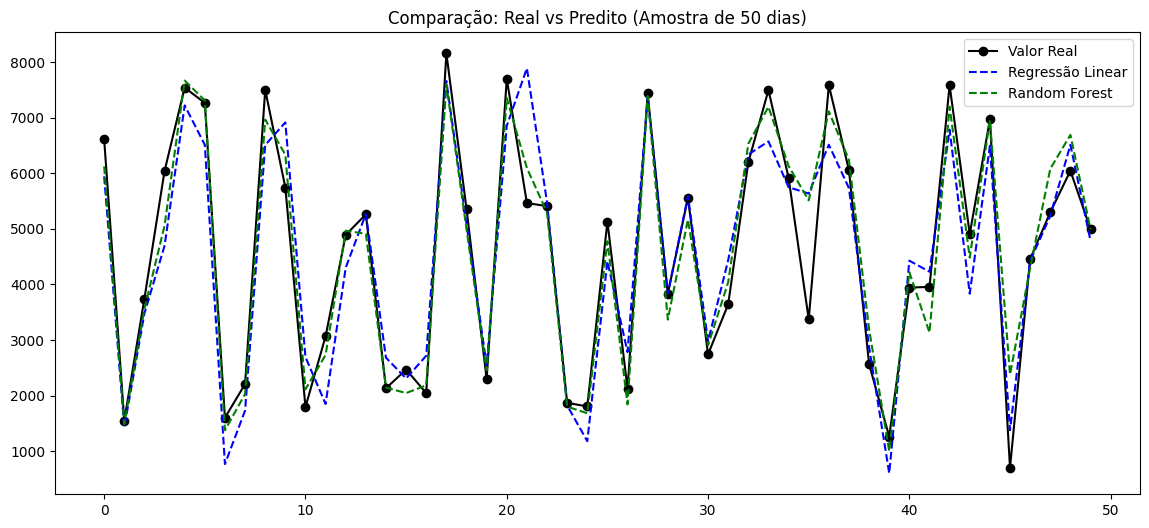

In [3]:
# Célula 2: Treinamento, Tuning e Avaliação
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# --- MODELO 1: REGRESSÃO LINEAR (Baseline) ---
print("Treinando Regressão Linear...")
lr_model = LinearRegression()
lr_model.fit(X_train_scaled, y_train)

# Previsões
y_pred_lr = lr_model.predict(X_test_scaled)

# --- MODELO 2: RANDOM FOREST (Com Cross-Validation para Hiperparâmetros) ---
print("Treinando Random Forest (isso pode demorar alguns segundos)...")

# Definindo os hiperparâmetros para testar
param_grid = {
    'n_estimators': [100, 200],      # Número de árvores
    'max_depth': [10, 20, None],     # Profundidade máxima da árvore
    'min_samples_split': [2, 5]      # Mínimo de amostras para dividir um nó
}

# Configurando o GridSearchCV (Cross-Validation com 5 dobras)
rf = RandomForestRegressor(random_state=42)
grid_search = GridSearchCV(estimator=rf, param_grid=param_grid, 
                           cv=5, scoring='neg_mean_squared_error', n_jobs=-1)

# Treinando (aqui ele testa todas as combinações)
grid_search.fit(X_train, y_train) # Random Forest não exige dados normalizados, usamos X_train normal

# Pegando o melhor modelo encontrado
best_rf_model = grid_search.best_estimator_
print(f"Melhores hiperparâmetros encontrados: {grid_search.best_params_}")

# Previsões com o melhor modelo
y_pred_rf = best_rf_model.predict(X_test)

# --- AVALIAÇÃO E COMPARAÇÃO ---

def avaliar_modelo(nome, y_real, y_pred):
    rmse = np.sqrt(mean_squared_error(y_real, y_pred))
    mae = mean_absolute_error(y_real, y_pred)
    r2 = r2_score(y_real, y_pred)
    print(f"--- {nome} ---")
    print(f"RMSE (Erro Quadrático Médio): {rmse:.2f}")
    print(f"MAE (Erro Absoluto Médio): {mae:.2f}")
    print(f"R² (Coeficiente de Determinação): {r2:.4f}\n")

print("\n=== RESULTADOS FINAIS ===")
avaliar_modelo("Regressão Linear", y_test, y_pred_lr)
avaliar_modelo("Random Forest (Tunado)", y_test, y_pred_rf)

# --- GRÁFICO DE COMPARAÇÃO ---
plt.figure(figsize=(14, 6))

# Pegamos apenas os primeiros 50 exemplos do teste para o gráfico não ficar poluído
x_ax = range(50)
plt.plot(x_ax, y_test[:50], label="Valor Real", color="black", linestyle="-", marker="o")
plt.plot(x_ax, y_pred_lr[:50], label="Regressão Linear", color="blue", linestyle="--")
plt.plot(x_ax, y_pred_rf[:50], label="Random Forest", color="green", linestyle="--")

plt.title("Comparação: Real vs Predito (Amostra de 50 dias)")
plt.legend()
plt.show()